# Парадокс Берксона

## Что это за парадокс?

Парадокс Берксона — это ситуация, когда **два независимых события становятся
статистически зависимыми (ассоциированными) внутри специально отобранной
подгруппы**.

**Почему так происходит?** Пусть отбор в группу происходит, когда реализуется
хотя бы одно из событий:

$$S = A \ \text{или}\ B.$$

Такая переменная $S$ называется **коллайдером**: в неё «входят» две
стрелки от $A$ и $B$. Если **обусловиться** на коллайдере (то есть оставить
только отобранных), пути $A$ и $B$ «открываются», и между ними появляется
зависимость — обычно отрицательная.

> *«Знание $B$ меняет нашу оценку вероятности $A$»* — именно это и есть
> условная вероятность, только вызванная **искажением отбора**, а не реальной
> связью в природе.

В этом ноутбуке мы смоделируем парадокс Берксона двумя способами:
1. **Дискретный пример** — две независимые болезни и госпитализация.
2. **Непрерывный пример** — два независимых признака и отбор «по сумме».


## 1. Дискретный пример: две болезни и больница

Пусть в популяции:

* событие $A$ — [редкое] заболевание А, $P(A) = 0.20$;
* событие $B$ — [фактор риска] состояние В, $P(B) = 0.30$;
* события $A$ и $B$ **независимы**: $P(A \mid B) = P(A)$.

В больницу $S$ человек попадает, если у него есть **хотя бы одно** из состояний:
$S = A \lor B$. Это и есть коллайдер.

Смоделируем большую популяцию и проверим независимость до отбора.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
rng = np.random.default_rng(42)

n = 300_000
p_a = 0.20   # P(A)
p_b = 0.30   # P(B)

# Моделируем БОЛЬШУЮ популяцию: события A и B генерируются НЕЗАВИСИМО
pop = pd.DataFrame({
    "A": rng.random(n) < p_a,
    "B": rng.random(n) < p_b,
})

p_A = pop["A"].mean()
p_A_given_B = pop.loc[pop["B"], "A"].mean()
p_A_given_notB = pop.loc[~pop["B"], "A"].mean()

print(f"Размер популяции: {n:,}")
print(f"P(A)              = {p_A:.3f}")
print(f"P(A | B)          = {p_A_given_B:.3f}")
print(f"P(A | не B)       = {p_A_given_notB:.3f}")
print(f"P(A | B) - P(A | не B) = {p_A_given_B - p_A_given_notB:+.3f}  "
      "(≈ 0 → независимы)")


Размер популяции: 300,000
P(A)              = 0.200
P(A | B)          = 0.200
P(A | не B)       = 0.200
P(A | B) - P(A | не B) = -0.000  (≈ 0 → независимы)


In [2]:
# Коллайдер: в выборку попадают, если есть A ИЛИ B
pop["selected"] = pop["A"] | pop["B"]
sel = pop[pop["selected"]].copy()

p_A_sel = sel["A"].mean()
p_A_given_B_sel = sel.loc[sel["B"], "A"].mean()
p_A_given_notB_sel = sel.loc[~sel["B"], "A"].mean()

print(f"Доля отобранных в больницу: P(S) = {pop['selected'].mean():.3f}")
print()
print("В ОТОБРАННОЙ группе (пациенты больницы):")
print(f"P(A | S)          = {p_A_sel:.3f}")
print(f"P(A | B, S)       = {p_A_given_B_sel:.3f}")
print(f"P(A | не B, S)    = {p_A_given_notB_sel:.3f}")
print(f"P(A | B, S) - P(A | не B, S) = "
      f"{p_A_given_B_sel - p_A_given_notB_sel:+.3f}  (отрицательная связь!)")


Доля отобранных в больницу: P(S) = 0.440

В ОТОБРАННОЙ группе (пациенты больницы):
P(A | S)          = 0.454
P(A | B, S)       = 0.200
P(A | не B, S)    = 1.000
P(A | B, S) - P(A | не B, S) = -0.800  (отрицательная связь!)


## 2. Сравнение таблиц сопряжённости

Построим распределение пар $(A, B)$ **в популяции** и **среди отобранных**.
В популяции доли должны соответствовать независимости, а внутри отбора клетка
«нет A и нет B» практически исчезает — именно это и порождает парадокс.


In [3]:
def joint_table(frame, title):
    tab = pd.crosstab(
        frame["A"].map({True: "есть A", False: "нет A"}),
        frame["B"].map({True: "есть B", False: "нет B"}),
        normalize=True,
    )
    print(title)
    display(tab.round(3))
    return tab

tab_pop = joint_table(pop, "Совместные доли в популяции:")
tab_sel = joint_table(sel, "Совместные доли среди отобранных (в больнице):")

print("Проверка независимости в популяции (ожидаем ≈ произведение краевых долей):")
print(f"P(A и B) факт      = {tab_pop.loc['есть A','есть B']:.3f}")
print(f"P(A) * P(B)        = {tab_pop['есть B'].sum() * tab_pop.loc['есть A'].sum():.3f}")


Совместные доли в популяции:


B,есть B,нет B
A,,
есть A,0.06,0.14
нет A,0.24,0.56


Совместные доли среди отобранных (в больнице):


B,есть B,нет B
A,,
есть A,0.136,0.318
нет A,0.546,0.000


Проверка независимости в популяции (ожидаем ≈ произведение краевых долей):
P(A и B) факт      = 0.060
P(A) * P(B)        = 0.060


,Популяция,Отобранные (больница)
P(A | B),0.2,0.2
P(A | не B),0.2,1.0


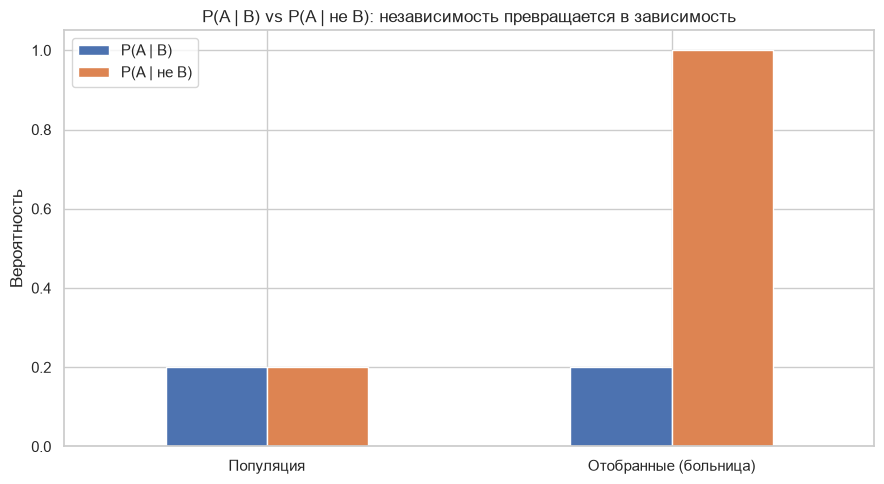

In [4]:
# Наглядно: условная вероятность P(A | B) в популяции и в отобранной группе
comparison = pd.DataFrame({
    "Популяция": [p_A_given_B, p_A_given_notB],
    "Отобранные (больница)": [p_A_given_B_sel, p_A_given_notB_sel],
}, index=["P(A | B)", "P(A | не B)"])

display(comparison.round(3))

ax = comparison.T.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_ylabel("Вероятность")
ax.set_title("P(A | B) vs P(A | не B): независимость превращается в зависимость")
ax.legend(title="")
plt.tight_layout()
plt.show()


## 3. Непрерывный пример: отбор «по сумме»

Более реалистичная версия. Пусть у человека есть два **независимых** признака:
$A \sim N(0, 1)$ и $B \sim N(0, 1)$. Например, математические и гуманитарные
способности — в популяции они не связаны.

Отбор происходит по **сумме**: в престижную программу попадают те, у кого
$A + B > \text{порог}$. Здесь коллайдер — факт отбора $A + B$.

Проверим корреляцию $A$ и $B$ **до** и **после** отбора.


In [5]:
m = 200_000
skill = pd.DataFrame({
    "A": rng.normal(0, 1, m),
    "B": rng.normal(0, 1, m),
})

corr_pop = skill[["A", "B"]].corr().iloc[0, 1]

# Порог отбора: верхние 20% по сумме A + B
threshold = np.quantile(skill["A"] + skill["B"], 0.80)
skill["selected"] = (skill["A"] + skill["B"]) > threshold
accepted = skill[skill["selected"]]

corr_sel = accepted[["A", "B"]].corr().iloc[0, 1]

print(f"Порог отбора (верхние 20%): A + B > {threshold:.3f}")
print(f"Корреляция A и B в популяции:      r = {corr_pop:+.3f}")
print(f"Корреляция A и B среди отобранных: r = {corr_sel:+.3f}")


Порог отбора (верхние 20%): A + B > 1.193
Корреляция A и B в популяции:      r = -0.003
Корреляция A и B среди отобранных: r = -0.645


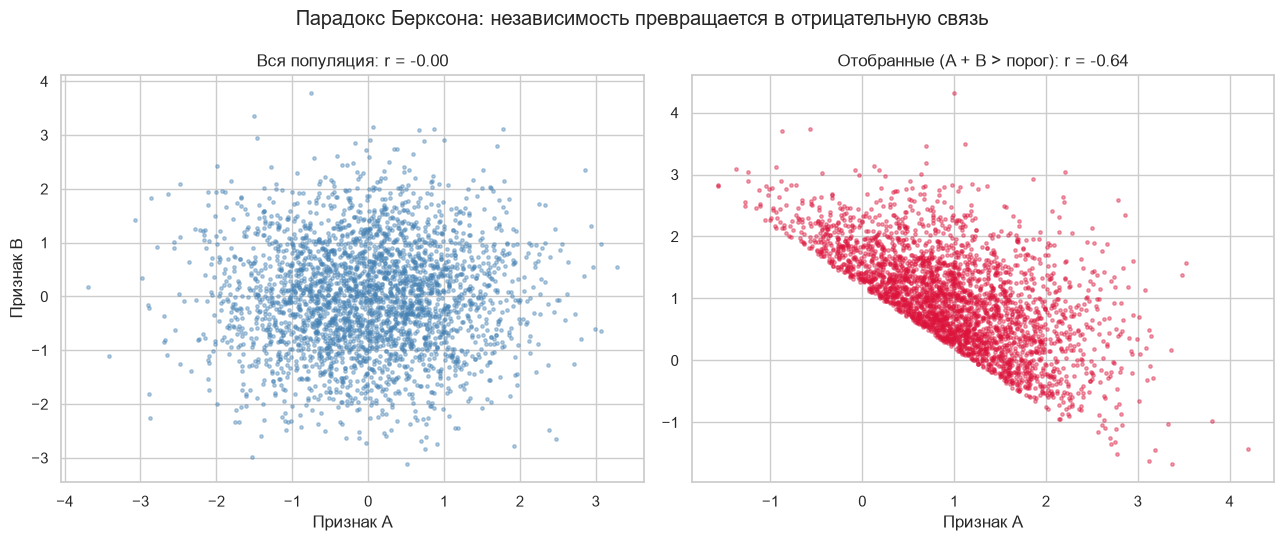

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sample_pop = skill.sample(3000, random_state=1)
axes[0].scatter(sample_pop["A"], sample_pop["B"], s=6, alpha=0.4, color="steelblue")
axes[0].set_title(f"Вся популяция: r = {corr_pop:+.2f}")
axes[0].set_xlabel("Признак A")
axes[0].set_ylabel("Признак B")

sample_sel = accepted.sample(3000, random_state=1)
axes[1].scatter(sample_sel["A"], sample_sel["B"], s=6, alpha=0.4, color="crimson")
axes[1].set_title(f"Отобранные (A + B > порог): r = {corr_sel:+.2f}")
axes[1].set_xlabel("Признак A")

plt.suptitle("Парадокс Берксона: независимость превращается в отрицательную связь")
plt.tight_layout()
plt.show()


## 4. Насколько силён эффект?

Чем **жёстче** отбор, тем сильнее «искажение» и тем более отрицательной
становится корреляция среди отобранных. Прогоним симуляцию для разных порогов
отбора.


,Доля отобранных,Корреляция A и B
0,0.40,-0.526
1,0.50,-0.468
2,0.60,-0.409
3,0.70,-0.341
4,0.80,-0.265
5,0.90,-0.170
6,0.95,-0.108


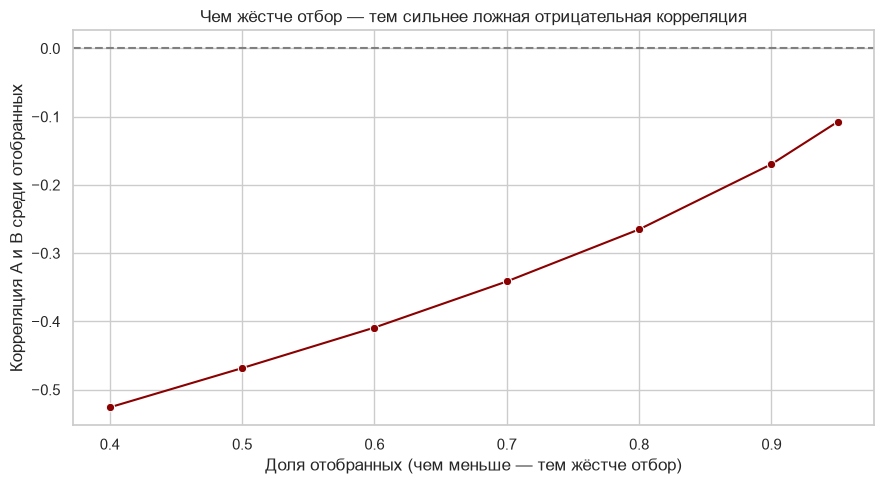

In [7]:
quantiles = [0.60, 0.50, 0.40, 0.30, 0.20, 0.10, 0.05]
corrs = []
fractions = []

for q in quantiles:
    thr = np.quantile(skill["A"] + skill["B"], q)
    mask = (skill["A"] + skill["B"]) > thr
    corrs.append(skill.loc[mask, ["A", "B"]].corr().iloc[0, 1])
    fractions.append(1 - q)

effect = pd.DataFrame({
    "Доля отобранных": fractions,
    "Корреляция A и B": corrs,
}).sort_values("Доля отобранных")

display(effect.round(3))

plt.figure(figsize=(9, 5))
sns.lineplot(data=effect, x="Доля отобранных", y="Корреляция A и B",
             marker="o", color="darkred")
plt.axhline(0, color="gray", linestyle="--")
plt.title("Чем жёстче отбор — тем сильнее ложная отрицательная корреляция")
plt.xlabel("Доля отобранных (чем меньше — тем жёстче отбор)")
plt.ylabel("Корреляция A и B среди отобранных")
plt.tight_layout()
plt.show()


## 5. Выводы

1. В **популяции** события $A$ и $B$ были построены **независимыми**:
   $P(A \mid B) \approx P(A \mid \text{не } B)$.
2. После отбора по коллайдеру $S = A \lor B$ внутри группы возникла
   **отрицательная зависимость**: $P(A \mid B, S) < P(A \mid \text{не } B, S)$.
3. В непрерывном примере корреляция сменилась с $\approx 0$ на выраженную
   **отрицательную**.
4. Чем **жёстче отбор**, тем **сильнее** искажение.

**Практический смысл.** Это частая ловушка в анализе данных: изучая только
отобранную подгруппу (пациенты больницы, студенты вуза, пассажиры лайнера),
можно обнаружить «связи», которых в реальности нет, — они порождены самим
механизмом отбора. Чтобы избежать парадокса Берксона, нужно анализировать
популяцию целиком либо явно учитывать механизм отбора.

**Как это связано с условной вероятностью?** Парадокс показывает, что
$P(A \mid B)$ зависит не только от природы $A$ и $B$, но и от того, **на что мы
обусловились** (на коллайдер). Небрежное обусловливание рождает вероятность,
которая вводит в заблуждение.
